# Example of the `aitlas` toolbox in the context of multi class image classification

This notebook shows a sample implementation of a multi class image classification using the `aitlas` toolbox and the Resisc45 dataset.

In [ ]:
from aitlas.datasets import Resisc45Dataset
from aitlas.models import ResNet50
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/NWPU-RESISC45", 
    "csv_file": "./data/NWPU-RESISC45/resisc45_train.csv"
    }
dataset = Resisc45Dataset(dataset_config)

## Show images from the dataset

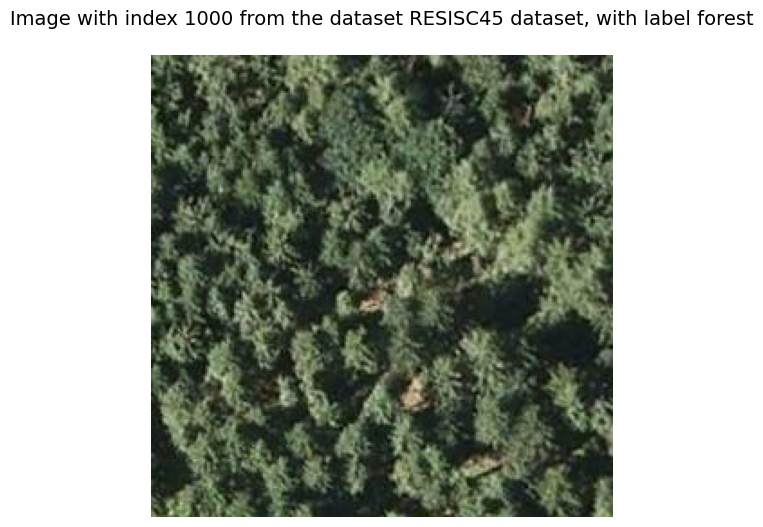

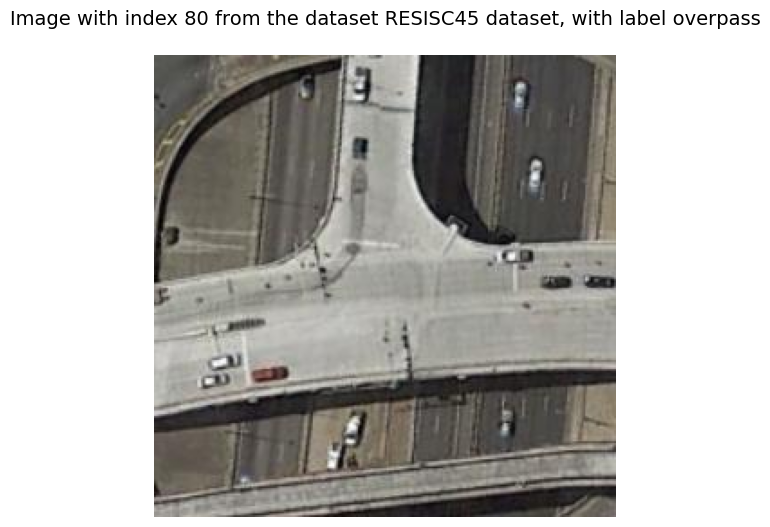

In [8]:
fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(80)

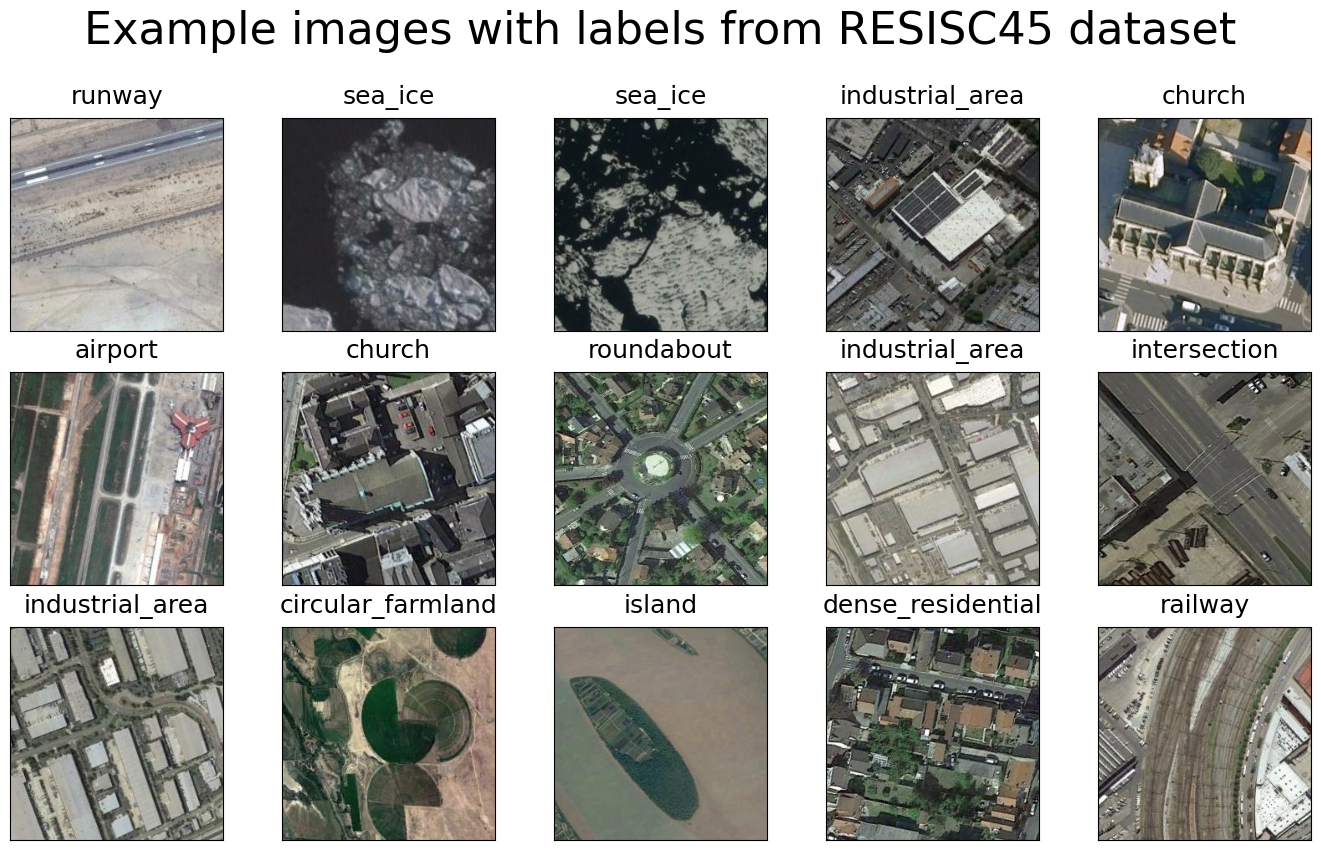

In [9]:
fig3 = dataset.show_batch(15)

## Inspect the data

In [10]:
dataset.show_samples()

,File name,Label
0,golf_course/golf_course_393.jpg,golf_course
1,basketball_court/basketball_court_298.jpg,basketball_court
2,commercial_area/commercial_area_567.jpg,commercial_area
3,cloud/cloud_546.jpg,cloud
4,wetland/wetland_390.jpg,wetland
5,sparse_residential/sparse_residential_620.jpg,sparse_residential
6,dense_residential/dense_residential_594.jpg,dense_residential
7,overpass/overpass_099.jpg,overpass
8,golf_course/golf_course_096.jpg,golf_course
9,railway/railway_542.jpg,railway


In [11]:
dataset.data_distribution_table()

,Label,Count
0,airplane,420
1,airport,420
2,baseball_diamond,420
3,basketball_court,420
4,beach,420
5,bridge,420
6,chaparral,420
7,church,420
8,circular_farmland,420
9,cloud,420


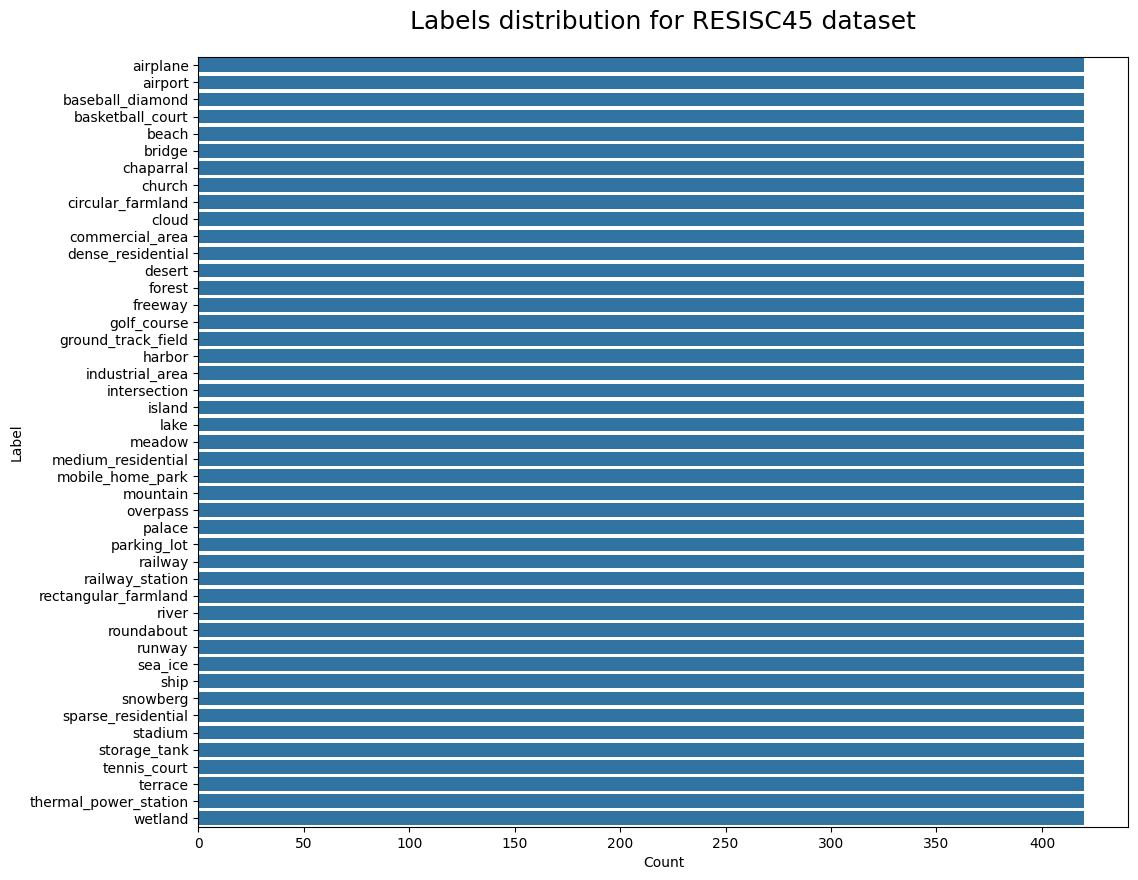

In [12]:
fig = dataset.data_distribution_barchart()

## Load train and test splits

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/NWPU-RESISC45",
    "csv_file": "./data/NWPU-RESISC45/resisc45_train.csv",
}

train_dataset = Resisc45Dataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor()

test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/NWPU-RESISC45",
    "csv_file": "./data/NWPU-RESISC45/resisc45_val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"],
}

test_dataset = Resisc45Dataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(18900, 6300)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/RESISC45"
model_config = {
    "num_classes": 45,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"],
}
model = ResNet50(model_config)
model.prepare()

## Training and evaluation

In [17]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id="1",
)

2026-08-24 10:23:12,713 INFO Starting training.
training: 100%|██████████| 1182/1182 [01:15<00:00, 15.66it/s]
2026-08-24 10:24:28,316 INFO epoch: 1, time: 76, loss:  1.25361
testing on train set: 100%|██████████| 1182/1182 [00:40<00:00, 29.11it/s]
2026-08-24 10:25:09,596 INFO Accuracy:0.9052910052910053, Precision Micro:0.9052910052910053, Precision Macro:0.9130656071480853, Precision Weighted:0.9130656071480852, Precision per Class:[0.99498747 0.87320574 0.97578692 0.9971831  0.95631068 0.98563218
 0.99054374 0.78606965 0.99744246 0.88486141 0.76817289 0.94609164
 0.92805755 0.97073171 0.57183499 0.99741602 0.92170022 0.98333333
 0.89537713 0.88045977 0.96059113 0.945      0.85684211 0.84340045
 0.85534591 0.8807947  0.89487871 0.83745583 0.93497758 0.89256198
 0.85714286 0.78895464 0.88939052 0.95049505 0.95114943 0.99287411
 0.96650718 0.99734748 0.94216867 0.95771144 0.97176471 0.86820084
 0.90930788 0.92079208 0.91709845], Recall Micro:0.9052910052910053, Recall Macro:0.9052910052

0.1536381039016008

## Predictions

2026-08-24 10:47:42,931 INFO Loading checkpoint /home/dragik/data/experiments/RESISC45/checkpoint.pth.tar
2026-08-24 10:47:45,370 INFO Loaded checkpoint /home/dragik/data/experiments/RESISC45/checkpoint.pth.tar at epoch 11


6300


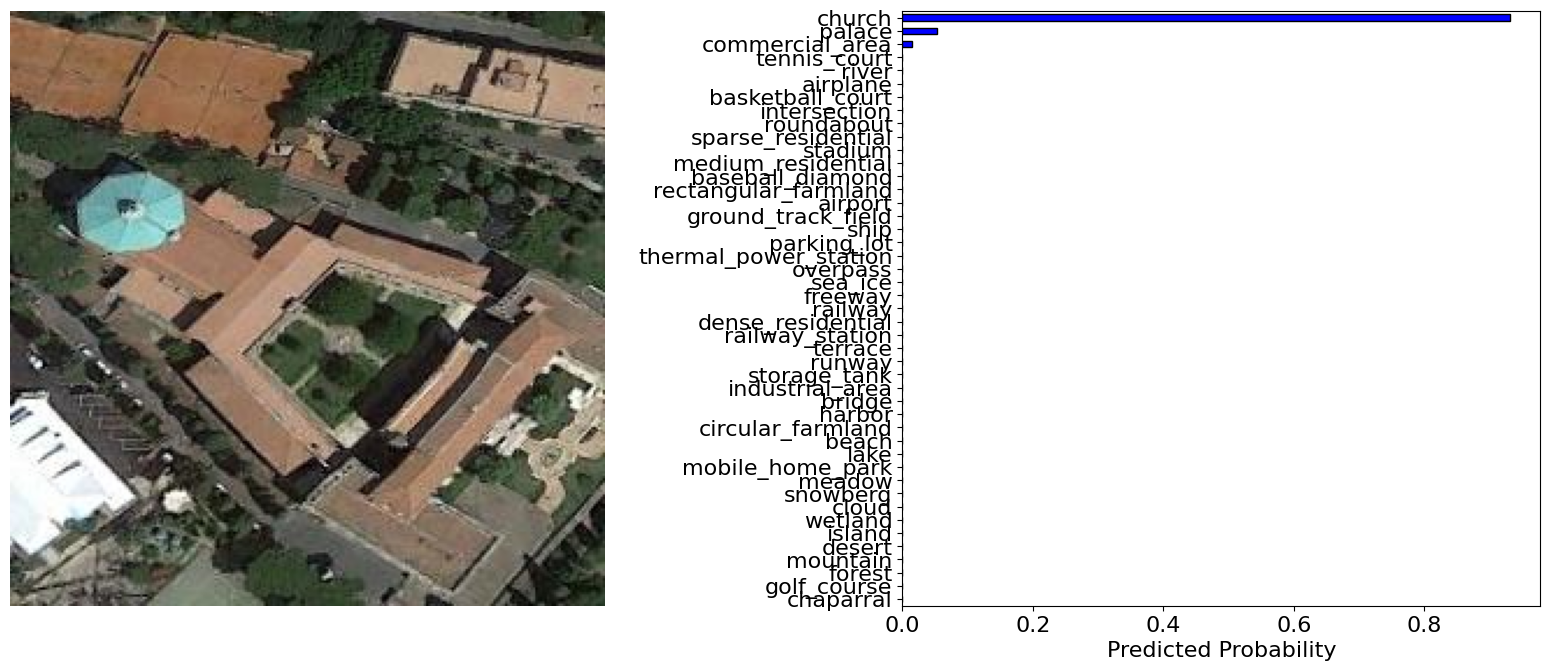

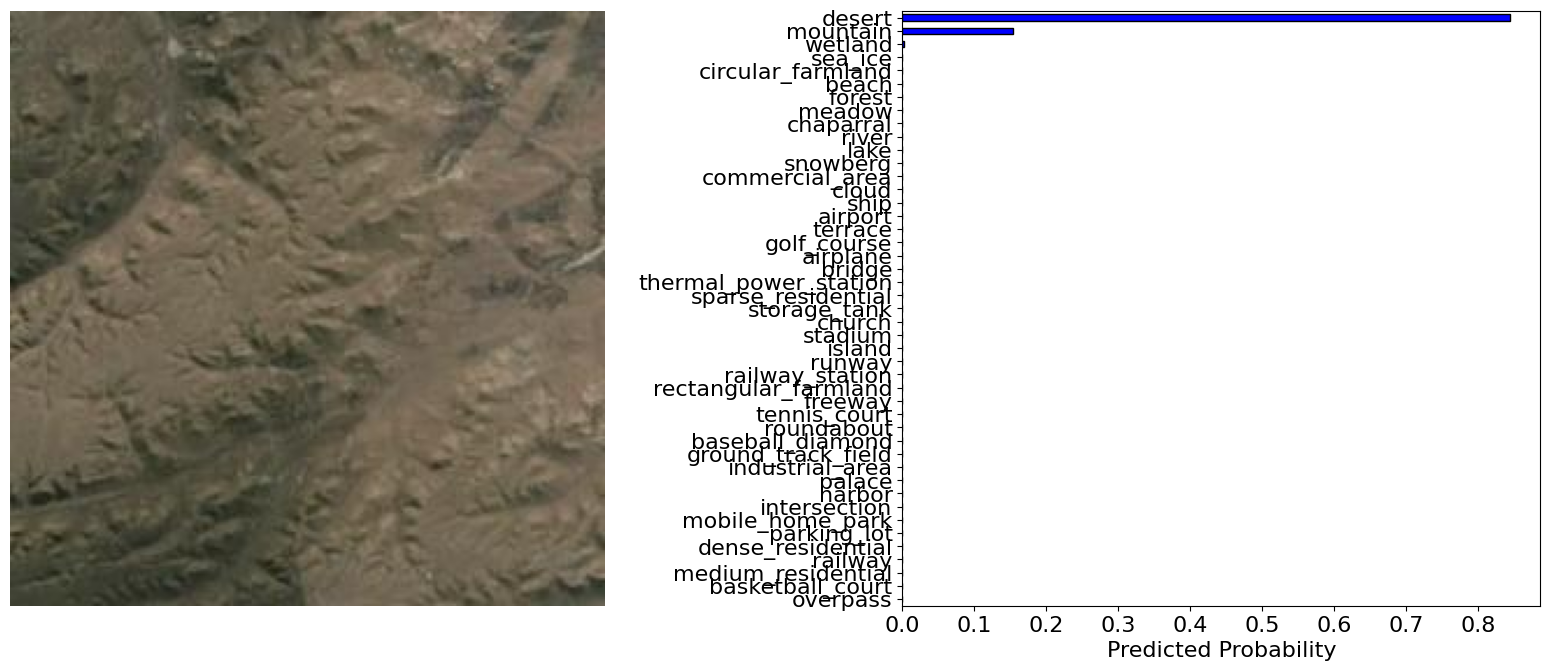

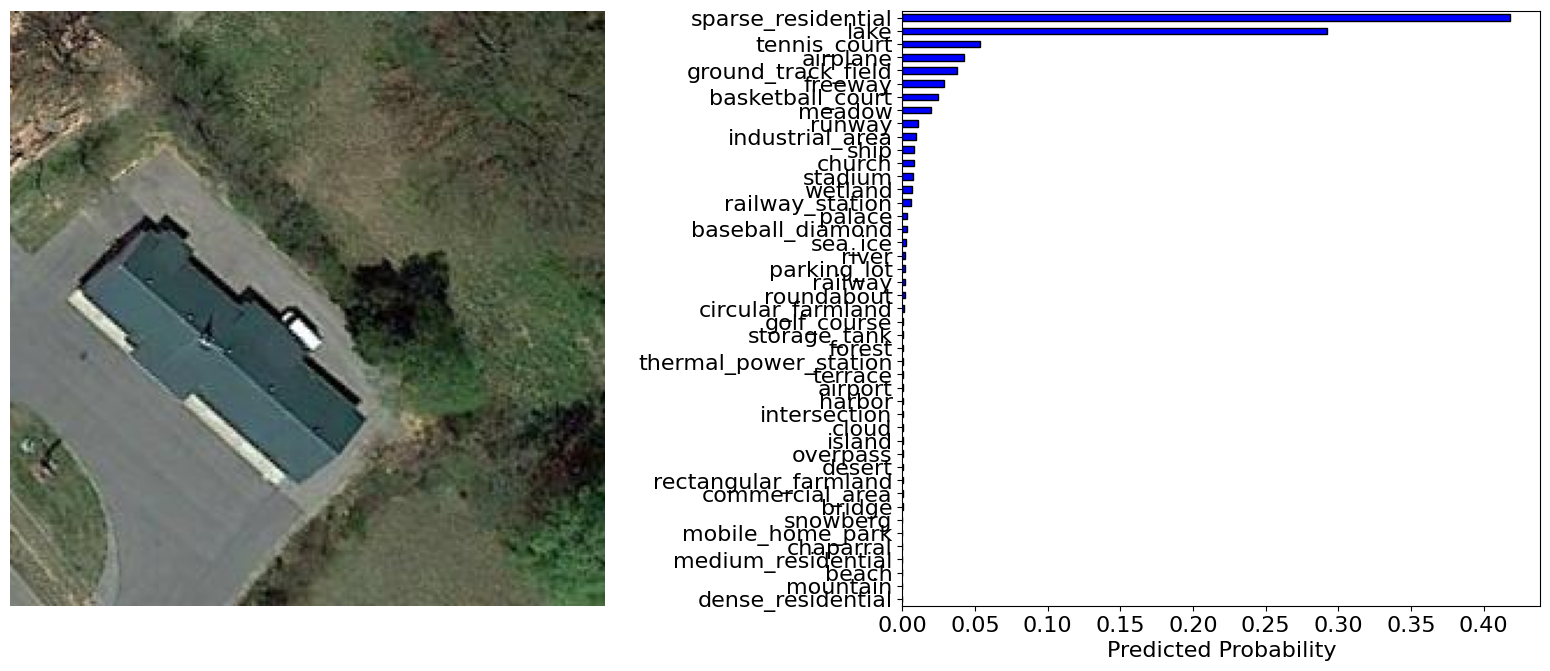

In [ ]:
model_path = "./data/experiments/RESISC45/checkpoint.pth.tar"
labels = [
    "airplane",
    "airport",
    "baseball_diamond",
    "basketball_court",
    "beach",
    "bridge",
    "chaparral",
    "church",
    "circular_farmland",
    "cloud",
    "commercial_area",
    "dense_residential",
    "desert",
    "forest",
    "freeway",
    "golf_course",
    "ground_track_field",
    "harbor",
    "industrial_area",
    "intersection",
    "island",
    "lake",
    "meadow",
    "medium_residential",
    "mobile_home_park",
    "mountain",
    "overpass",
    "palace",
    "parking_lot",
    "railway",
    "railway_station",
    "rectangular_farmland",
    "river",
    "roundabout",
    "runway",
    "sea_ice",
    "ship",
    "snowberg",
    "sparse_residential",
    "stadium",
    "storage_tank",
    "tennis_court",
    "terrace",
    "thermal_power_station",
    "wetland",
]
transform = ResizeCenterCropToTensor()
model.load_model(model_path)

test_dataset_config = {
    "data_dir": "./data/NWPU-RESISC45",
    "csv_file": "./data/NWPU-RESISC45/resisc45_test.csv"
}

test_dataset = Resisc45Dataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[100][0]
fig = model.predict_image(image, labels, transform)